$\textbf{Import libraries}$

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import scipy
from scipy.stats import poisson

$\textbf{Poisson probability estimation}$

In [11]:
class PoissonApproximation:
    def __init__(self, lamb, epsilon=0.01):
        """
        Initialize PoissonApproximation class with lamb and optional epsilon.
        
        Parameters:
        lamb (float): The lambda parameter of the Poisson distribution.
        epsilon (float): The tolerance level for approximation.
        """
        self.lamb = lamb
        self.alpha = 0
        self.beta = 0
        self.vals = {}
        self.calculate_vals(epsilon) # Calculating values based on epsilon

    def calculate_vals(self, epsilon):
        """
        Calculate Poisson distribution values within epsilon tolerance.
        
        Parameters:
        epsilon (float): The tolerance level for approximation.
        """
        while True:
            pmf_alpha = poisson.pmf(self.alpha, self.lamb)
            if pmf_alpha <= epsilon:
                self.alpha += 1
            else:
                self.vals[self.alpha] = pmf_alpha # Storing PMF value for alpha
                self.beta = self.alpha + 1
                break

        while True:
            pmf_beta = poisson.pmf(self.beta, self.lamb)
            if pmf_beta <= epsilon:
                break
            else:
                self.vals[self.beta] = pmf_beta  # Storing PMF value for beta
                self.beta += 1

        total_pmf = sum(self.vals.values())
        added_val = (1 - total_pmf) / (self.beta - self.alpha)
        self.vals = {key: val + added_val for key, 
                     val in self.vals.items()}     # Normalizing PMF values

    def f(self, n):
        """
        Get the approximate PMF value for a given value of n.
        
        Parameters:
        n (int): The value for which PMF is to be calculated.
        
        Returns:
        float: The approximate PMF value for the given n.
        """
        
        # Return PMF value for n if present, otherwise return 0
        return self.vals.get(n, 0)


$\textbf{Location}$

In [12]:
class location:
    def __init__(self, request, returned):
        self.alpha = request    #value of lamb for requests
        self.beta = returned     #value of lamb for returns
        self.poisson_alpha = PoissonApproximation(self.alpha)
        self.poisson_beta = PoissonApproximation(self.beta)


In [13]:
# Create Location instances A and B with specified request and return 
A = location(3,3)
B = location(4,2)

$\textbf{CONSTANTS initialisations}$

In [14]:
max_car = 20
gamma = 0.9
credit_reward = 10
moving_reward = -2

$\textbf{Initialisation of the Value and policy matrices}$

In [15]:
#Initializing the value and policy matrices. Initial policy 
# has zero value for all states.
value = np.zeros((max_car+1, max_car+1))
policy = value.copy().astype(int)

$\textbf{Action Apllied}$

In [18]:
def apply_action(state, action):
    """
    Apply the given action to the current state and return the new state.

    Parameters:
    state  : tuple of integers representing the number of cars at locations A and B.
    action : number of cars transferred from A to B.

    Returns:
    list: a list representing the new state after applying the action.
    """
    return [max(min(state[0] - action, max_car),0) , 
            max(min(state[1] + action, max_car),0)]

$\textbf{Calculate the expected reward}$

In [19]:
def expected_reward(state, action):
    global value
    """
    Calculate the expected reward for a given state and action.

    Parameters:
    state  : tuple of integers representing the number of cars at locations A and B.
    action : number of cars transferred from A to B.

    Returns:
    float: the expected reward for the given state and action.
    """
    
    q = 0 #reward
    new_state = apply_action(state, action) # Apply the action to get the new state

    # adding reward for moving cars from one location to another (which is negative)
    q = q + moving_reward * abs(action)

   # Iterate through all possible combinations of requests and returns at both locations
    for A_alpha in range(A.poisson_alpha.alpha, A.poisson_alpha.beta):
        for B_alpha in range(B.poisson_alpha.alpha, B.poisson_alpha.beta):
            for A_beta in range(A.poisson_beta.alpha, A.poisson_beta.beta):
                for B_beta in range(B.poisson_beta.alpha, B.poisson_beta.beta):
                    """
                    A_alpha : sample of cars requested at location A
                    A_beta : sample of cars returned at location A
                    B_alpha : sample of cars requested at location B
                    B_beta : sample of cars returned at location B
                    p  : probability of this event happening
                    """

                    # Calculate the probability of this event happening
                    p = A.poisson_alpha.vals[A_alpha] * B.poisson_alpha.vals[B_alpha] * A.poisson_beta.vals[A_beta] * B.poisson_beta.vals[B_beta]
                    
                    # Calculate the number of valid requests at each location
                    valid_requests_A = min(new_state[0], A_alpha)
                    valid_requests_B = min(new_state[1], B_alpha)

                    # Calculate reward based on valid requests
                    rew = (valid_requests_A + valid_requests_B)*(credit_reward)

                   # Calculate the new state based on the values of the four random variables
                    new_s = [0,0]
                    new_s[0] = max(min(new_state[0] - valid_requests_A + A_beta, max_car),0)
                    new_s[1] = max(min(new_state[1] - valid_requests_B + B_beta, max_car),0)

                    # Bellman's equation: Update reward with discounted future reward
                    q += p * (rew + gamma * value[new_s[0]][new_s[1]])

    return q

$\textbf{Value Interation}$

In [20]:
def value_iteration():
    global value

    epsilon = 0.01  # Convergence threshold
    max_iterations = 100  # Maximum number of iterations

    # Iterate until convergence or maximum iterations reached
    for ite in range(max_iterations):
        delta = 0

        # Iterate over all states
        for i in range(value.shape[0]):
            for j in range(value.shape[1]):
                old_val = value[i][j]
                max_val = float('-inf') # Initialize maximum value
                best_action = None

                # Find the action that maximizes the expected reward
                for act in range(-min(j, 5), min(i, 5) + 1):
                    sigma = expected_reward([i, j], act) # Calculate expected reward
                    if sigma > max_val:  # Update maximum value and best action
                        max_val = sigma
                        best_action = act

                value[i][j] = max_val       # Update value function
                policy[i][j] = best_action  # Update policy

                # Update change in value function
                delta = max(delta, abs(value[i][j] - old_val))

        # Check for convergence
        if delta < epsilon:
            break

        # Print policy matrix every 10 iterations
        if ite%10 == 0:
            print(f'After {ite+1} iteration, the policy matrix is: ')
            print('--------------------------------------------------------------')
            print(policy)
            print('---------------------------------------------------------------')

    return value, policy

# Run value iteration
value ,policy = value_iteration() # Optimal policy is stored in the 'policy' matrix


After 1 iteration, the policy matrix is: 
--------------------------------------------------------------
[[ 0  0  0  0 -1 -2 -2 -2 -3 -3 -3 -4 -4 -4 -4 -4 -4 -4 -4 -4 -4]
 [ 0  0  0  0  0 -1 -1 -2 -2 -2 -2 -2 -2 -2 -2 -2 -2 -2 -2 -2 -2]
 [ 1  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [ 2  1  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  2  2  2  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [ 3  3  3  2  2  2  2  2  2  2  2  2  2  1  1  1  1  1  1  2  2]
 [ 4  3  3  3  3  3  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2]
 [ 4  4  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  2]
 [ 4  4  4  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3]
 [ 4  4  4  4  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3]
 [ 4  4  4  4  4  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3]
 [ 4  4  4  4  4  4  4  4  4  3  3  3  3  3  3  3  3  4  3  3  3]
 [ 5  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  3  3]
 [ 5  4  4  4  4  4  4  4  4  4  4  4

$\textbf{The optimal policy is:}$

In [21]:
print(policy)

[[ 0  0  0  0  0  0  0  0 -1 -1 -2 -2 -2 -3 -3 -3 -3 -3 -4 -4 -4]
 [ 0  0  0  0  0  0  0  0  0 -1 -1 -1 -2 -2 -2 -2 -2 -3 -3 -3 -3]
 [ 0  0  0  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -2 -2 -2 -2 -2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1]
 [ 1  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  3  2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 4  3  3  2  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 4  4  3  3  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  4  4  3  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  4  3  2  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  4  3  3  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  4  4  3  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  5

$\textbf{Heatmap for the optimal policy}$

Text(0.5, 1.0, 'Optimal Policy')

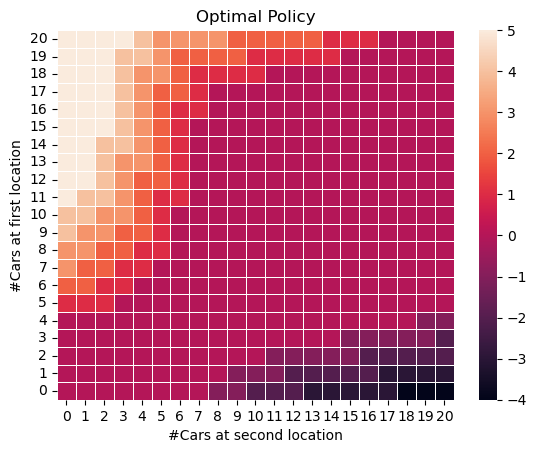

In [26]:
ax = sns.heatmap(policy, linewidth=0.5)
ax.invert_yaxis()
ax.set_xlabel('#Cars at second location')
ax.set_ylabel('#Cars at first location')
ax.set_title('Optimal Policy')